In [1]:
!mkdir data

!curl -s -o data/train-images-idx3-ubyte.gz https://ossci-datasets.s3.amazonaws.com/mnist/train-images-idx3-ubyte.gz
!curl -s -o data/train-labels-idx1-ubyte.gz https://ossci-datasets.s3.amazonaws.com/mnist/train-labels-idx1-ubyte.gz
!curl -s -o data/t10k-images-idx3-ubyte.gz https://ossci-datasets.s3.amazonaws.com/mnist/t10k-images-idx3-ubyte.gz
!curl -s -o data/t10k-labels-idx1-ubyte.gz https://ossci-datasets.s3.amazonaws.com/mnist/t10k-labels-idx1-ubyte.gz

In [2]:
import numpy as np
import gzip
import matplotlib.pyplot as plt
import time

In [3]:
w, h = 28, 28
wh = w * h
s = 300
k = 10


def load_images(path):
    with gzip.open(path, "rb") as f:
        return np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, wh)


def load_labels(path):
    with gzip.open(path, "rb") as f:
        return np.frombuffer(f.read(), np.uint8, offset=8)


X_train = load_images("data/train-images-idx3-ubyte.gz").astype(np.float32) / 255
y_train = load_labels("data/train-labels-idx1-ubyte.gz")
X_test = load_images("data/t10k-images-idx3-ubyte.gz").astype(np.float32) / 255
y_test = load_labels("data/t10k-labels-idx1-ubyte.gz")
Y_train = np.eye(k, dtype=np.float32)[y_train]

print(f"train: {X_train.shape}, {y_train.shape}, test: {X_test.shape}, {y_test.shape}")
print(f"train: {X_train[0].shape}, test: {X_test[0].shape}")

train: (60000, 784), (60000,), test: (10000, 784), (10000,)
train: (784,), test: (784,)


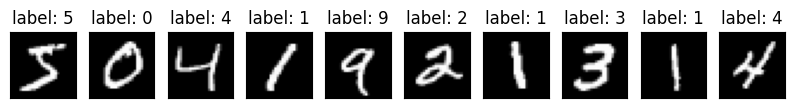

In [4]:
plt.figure(figsize=(10, 1))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.setp(plt.gcf().get_axes(), xticks=[], yticks=[])
    plt.imshow(X_train[i].reshape(w, h), cmap="gray")
    plt.title(f"label: {y_train[i]}")
plt.show()

In [5]:
def init_params(rng):
    # nn.init.xavier_normal_(w, gain=nn.init.calculate_gain("relu"))

    w_h = (rng.normal(0, (np.sqrt(2) * np.sqrt(2 / (wh + s))) ** 2, (wh, s))).astype(
        np.float32
    )
    b_h = np.zeros(s, np.float32)
    w_o = (rng.normal(0, (np.sqrt(2) * np.sqrt(2 / (s + k))) ** 2, (s, k))).astype(
        np.float32
    )
    b_o = np.zeros(k, np.float32)
    return w_h, b_h, w_o, b_o


def forward(x):
    p = x @ w_h + b_h

    h = np.maximum(p, 0)

    v = h @ w_o + b_o

    e = np.exp(v - v.max(axis=1, keepdims=True))
    u = e / e.sum(axis=1, keepdims=True)

    return p, h, u


def update(x, y):
    n = len(x)
    p, h, u = forward(x)

    # dv = (u * y.sum(axis=1, keepdims=True) - y) / n
    # y.sum(axis=1, keepdims=True) = 1 for MNIST
    dv = (u - y) / n
    dp = (dv @ w_o.T) * (p > 0)

    dw_h = x.T @ dp
    db_h = dp.sum(axis=0)
    dw_o = h.T @ dv
    db_o = dv.sum(axis=0)

    return dw_h, db_h, dw_o, db_o

In [6]:
%%time

lr = 0.1
batch_size = 32
epochs = 20

rng = np.random.default_rng(0)
w_h, b_h, w_o, b_o = init_params(rng)

for epoch in range(epochs):
    perm = rng.permutation(len(X_train))

    t0 = time.time()
    for i in range(0, len(perm), batch_size):
        idx = perm[i : i + batch_size]
        dw_h, db_h, dw_o, db_o = update(X_train[idx], Y_train[idx])
        w_h -= lr * dw_h
        b_h -= lr * db_h
        w_o -= lr * dw_o
        b_o -= lr * db_o

    u_train = forward(X_train)[2]
    y_logu = np.log(u_train[np.arange(len(y_train)), y_train])
    loss = -y_logu.mean()

    elapsed = time.time() - t0

    err = (u_train.argmax(axis=1) != y_train).mean()
    print(f"Epoch {epoch+1:2d}/{epochs}: {loss=:.4f} {err=:.4%} {elapsed=:.4f}")

Epoch  1/20: loss=0.2108 err=6.0150% elapsed=1.3750
Epoch  2/20: loss=0.1196 err=3.3450% elapsed=1.5065
Epoch  3/20: loss=0.0884 err=2.5033% elapsed=2.0141
Epoch  4/20: loss=0.0706 err=1.9983% elapsed=1.2852
Epoch  5/20: loss=0.0584 err=1.6500% elapsed=1.8113
Epoch  6/20: loss=0.0510 err=1.4600% elapsed=1.2253
Epoch  7/20: loss=0.0368 err=0.9317% elapsed=1.2850
Epoch  8/20: loss=0.0350 err=0.9583% elapsed=1.2052
Epoch  9/20: loss=0.0278 err=0.6500% elapsed=1.2286
Epoch 10/20: loss=0.0279 err=0.7133% elapsed=1.2013
Epoch 11/20: loss=0.0220 err=0.4767% elapsed=1.1963
Epoch 12/20: loss=0.0176 err=0.3500% elapsed=1.2013
Epoch 13/20: loss=0.0145 err=0.2200% elapsed=1.2942
Epoch 14/20: loss=0.0126 err=0.1767% elapsed=1.2661
Epoch 15/20: loss=0.0131 err=0.2283% elapsed=1.1773
Epoch 16/20: loss=0.0100 err=0.1133% elapsed=1.1878
Epoch 17/20: loss=0.0089 err=0.0883% elapsed=1.1812
Epoch 18/20: loss=0.0075 err=0.0617% elapsed=1.2435
Epoch 19/20: loss=0.0065 err=0.0433% elapsed=1.1851
Epoch 20/20:

In [7]:
u_test = forward(X_test)[2]
y_pred = u_test.argmax(axis=1)
err = (y_pred != y_test).mean()
acc = 1 - err
print(f"{err=:.4%} {acc=:.4%}")

err=1.7900% acc=98.2100%
